<a href="https://colab.research.google.com/github/Camimichelini0406/2026_Intro_Python/blob/main/FEEDBACK_CAMILLE_MICHELINI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 I decide to redo the exercice 1.6, because I found it very challenging to use the tools for the exclusion of the different states, and the plotting of the map of the US with the hurricanes.

# IMPORT


In [1]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

The first questions :


In [2]:
# Q1) Import geopandas (as gpd), pandas, and matplotlib

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Q2) Read the data with the geopandas function
country = gpd.read_file(states_path)
print(country)

# Q3) Print out the first few lines of the data
country.head(3)



         GEO_ID STATE                  NAME LSAD  CENSUSAREA  \
0   0400000US01    01               Alabama        50645.326   
1   0400000US02    02                Alaska       570640.950   
2   0400000US04    04               Arizona       113594.084   
3   0400000US05    05              Arkansas        52035.477   
4   0400000US06    06            California       155779.220   
5   0400000US08    08              Colorado       103641.888   
6   0400000US09    09           Connecticut         4842.355   
7   0400000US10    10              Delaware         1948.543   
8   0400000US11    11  District of Columbia           61.048   
9   0400000US12    12               Florida        53624.759   
10  0400000US13    13               Georgia        57513.485   
11  0400000US15    15                Hawaii         6422.628   
12  0400000US16    16                 Idaho        82643.117   
13  0400000US17    17              Illinois        55518.930   
14  0400000US18    18               Indi

,GEO_ID,STATE,NAME,LSAD,CENSUSAREA,geometry
0,0400000US01,01,Alabama,,50645.326,"MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ..."
1,0400000US02,02,Alaska,,570640.950,"MULTIPOLYGON (((-166.10574 53.98861, -166.0752..."
2,0400000US04,04,Arizona,,113594.084,"POLYGON ((-112.53859 37.00067, -112.53454 37.0..."


Q4) Have a look at the data on a map using geopandas' .plot() method.

Exclude Alaska and Hawaii using the NAME attribute and pandas' .isin() method. Specify the figsize to be 30 x 20.

My error was that I wanted to select all the states and not take Alaska and Hawaii because I didn't realise that I could use ~.

So to correct :

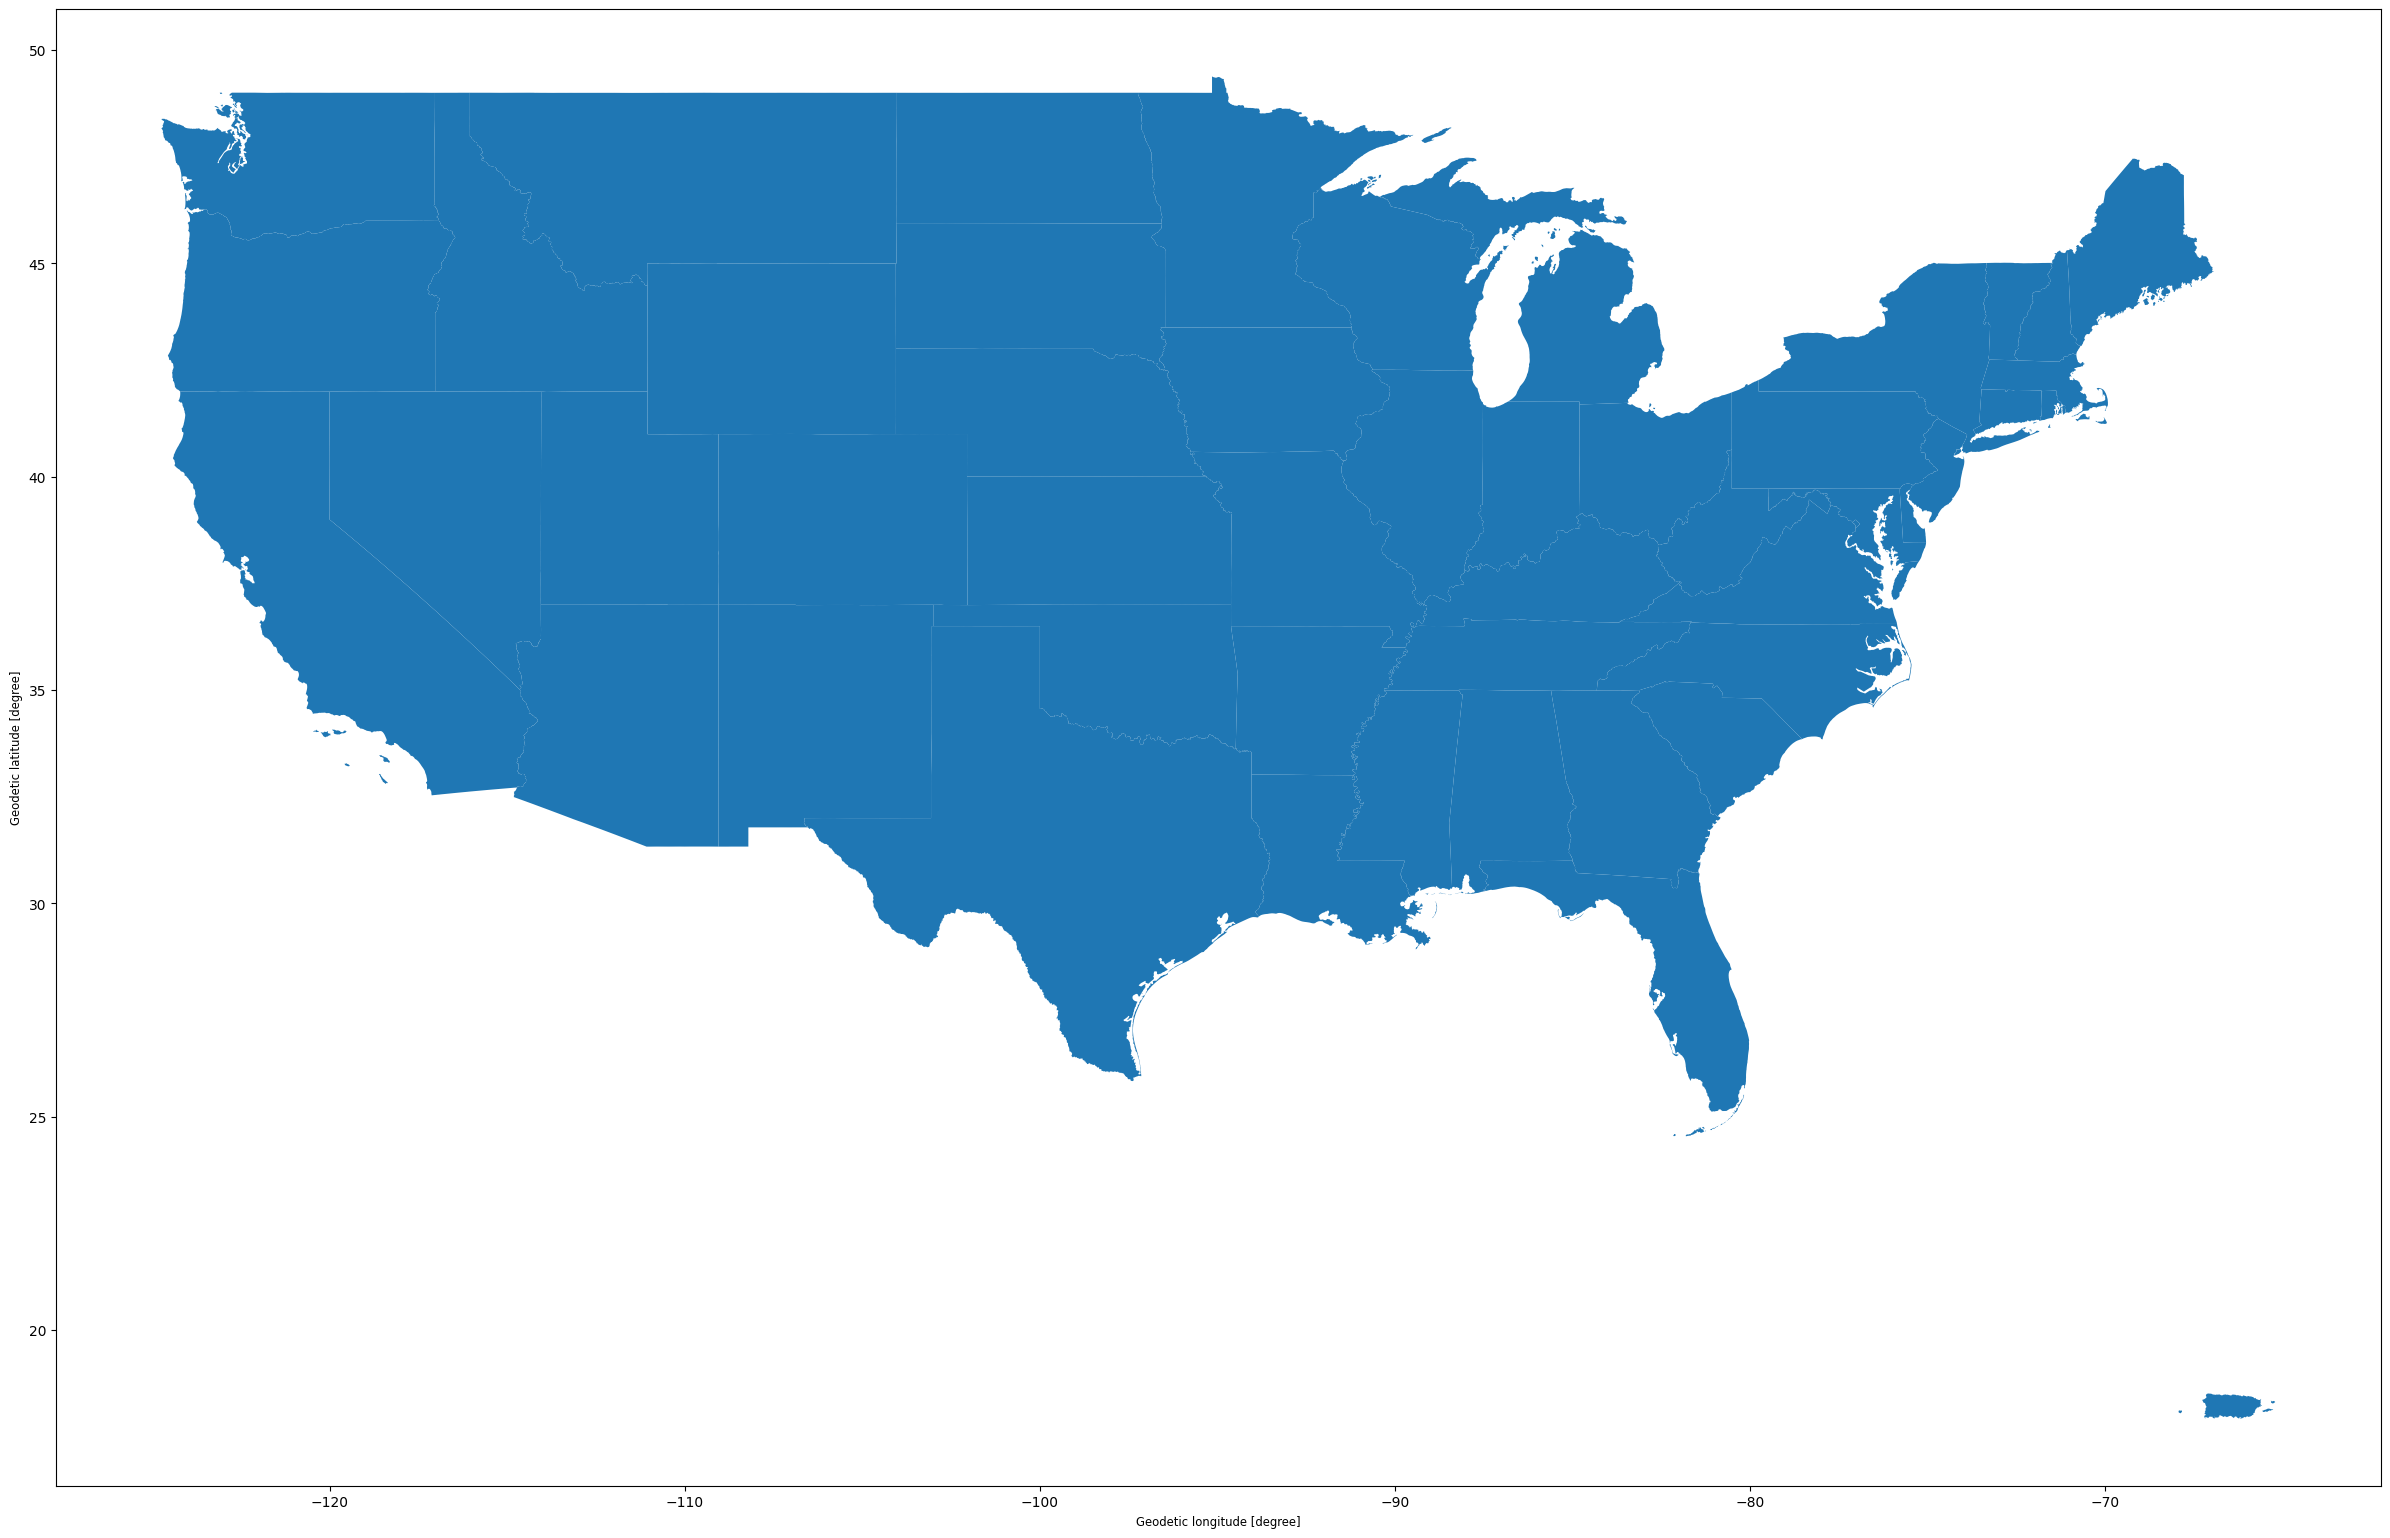

In [4]:
# Plot the US states (Alaska and Hawaii excluded)
US= country[~country["NAME"].isin(["Alaska","Hawaii"])].plot(figsize=(30,20))

In [6]:
# Pre-supplied: read in the hurricane Florence data, drop the advisory bookkeeping columns,
# fix the longitude sign, and have a look at the dataframe.
# The Long column holds a positive "degrees west" magnitude, not a signed longitude -- a common
# quirk of NHC advisory data.
florence = pd.read_csv(track_path)
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
florence["Long"] = 0 - florence["Long"]
florence.head(3)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six


In [7]:
# Q5) Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(
    florence,
    geometry=gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326"
)
gdf_florence.head()

,Date,Lat,Long,Wind,Pres,Movement,Type,Name,geometry
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-18.4 12.9)
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19 12.9)
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19.4 12.9)
3,08/30/2018 20:00,13.1,-20.4,30,1007,W at 11 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-20.4 13.1)
4,08/30/2018 23:00,13.2,-20.9,35,1007,W at 13 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-20.9 13.2)


Q6) Plot the US states map (without Alaska and Hawaii) and hurricane Florence together.

Draw the states as a base map, then plot the hurricane positions on top in a colour that stands out.

My error was that I didn't know that I could plot the two different plot on the same one. I didn't realise that I could just use the same ax for both of the plot.

My solution

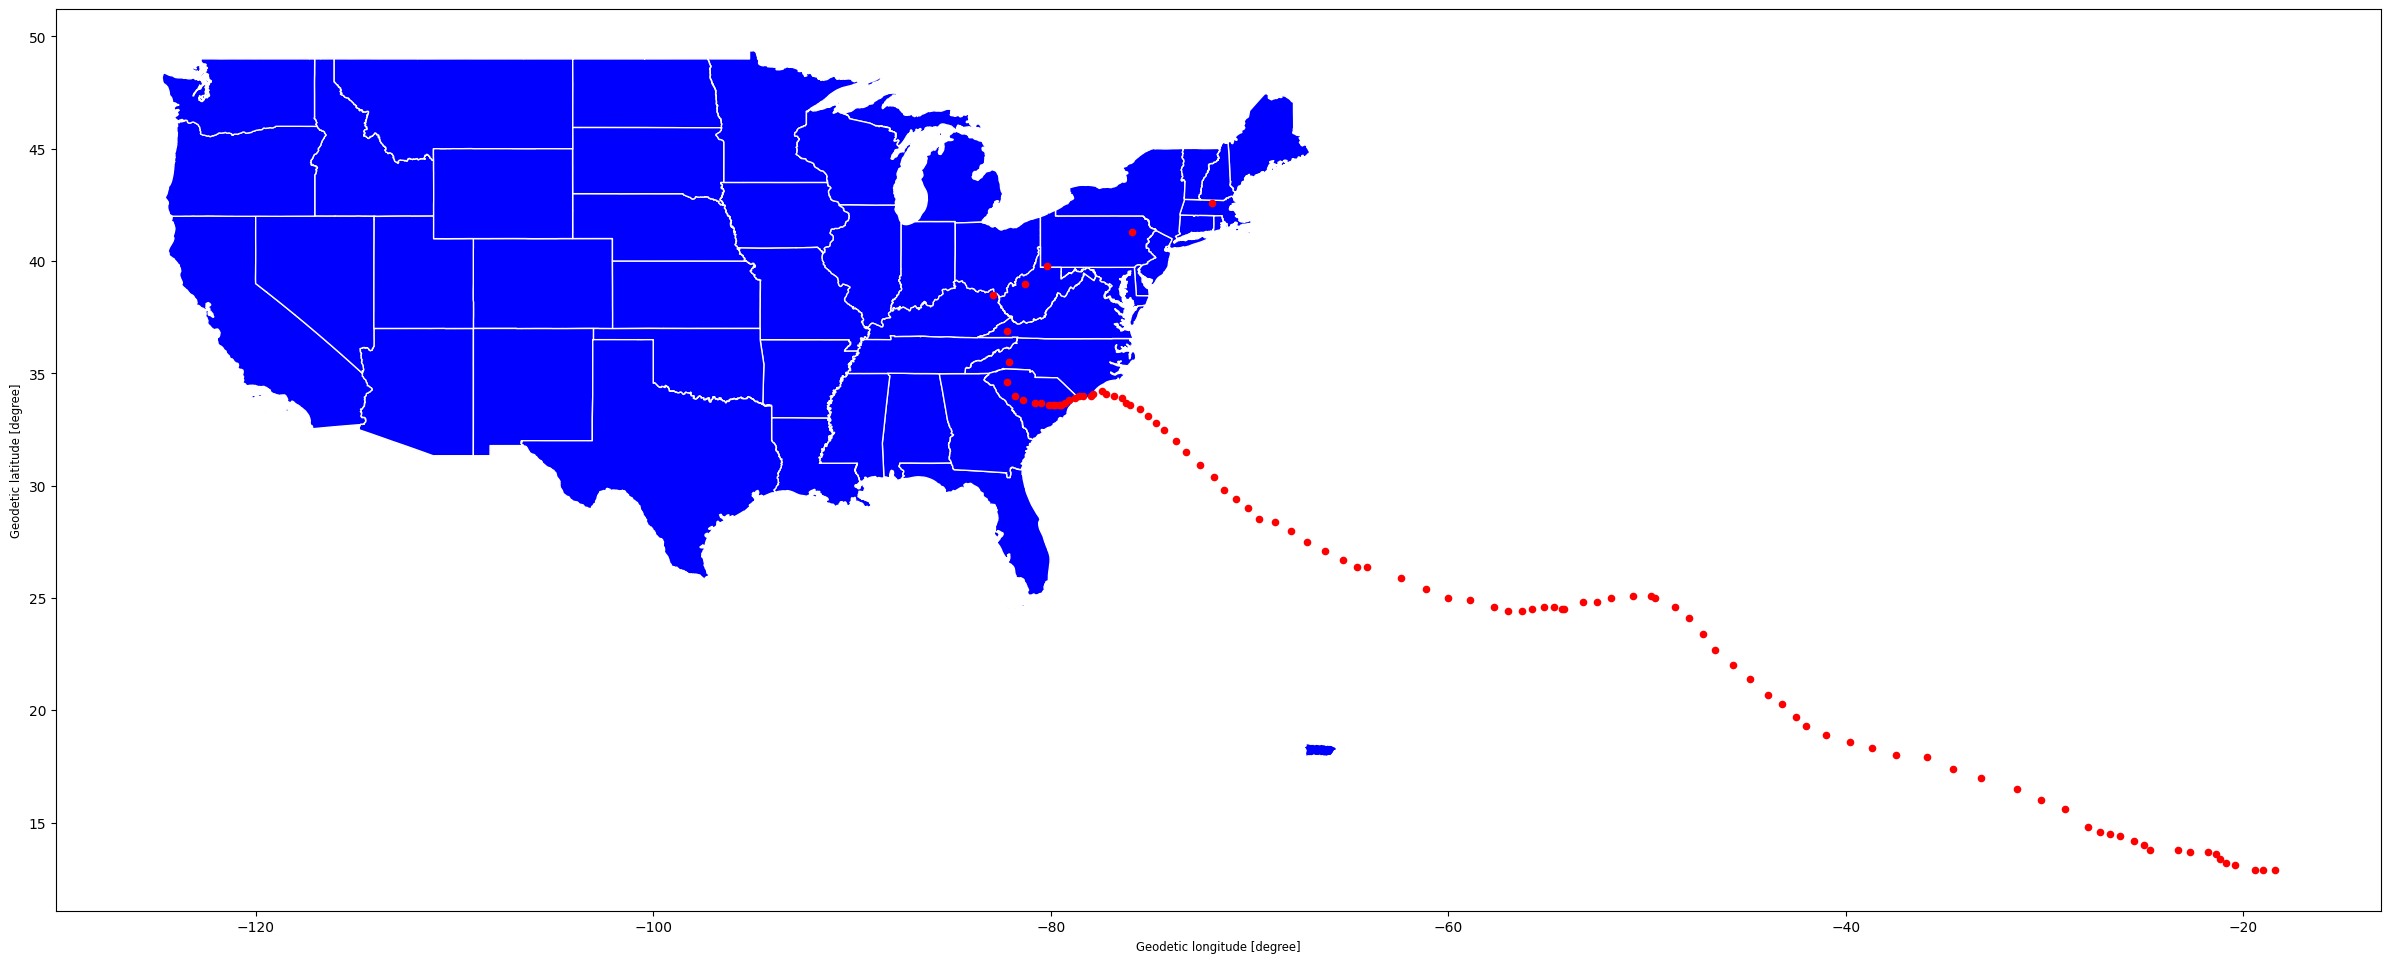

In [11]:
# Plot to see the hurricane overlay the US map, with the hurricane position on top
conus = country[~country["NAME"].isin(["Alaska", "Hawaii"])]#also here I had to rename my US to use it in this figure

fig, ax = plt.subplots(figsize=(30, 20)) # dans un domaine x y
conus.plot(ax=ax, color="blue", edgecolor="white") #fond de carte, ax=ax càd que on doit mettre le graphique dans l'axe défini au-dessus, color c'est des états
gdf_florence.plot(ax=ax, color="red", markersize=20) # la fonction on veut la dessiner sur le même fond de carte ax, et après on donne la couleur
plt.show()